# Resultados no conjunto de teste

Os modelos já treinados são carregados e avaliados. A escolha do modelo da análise de erros usa o F1 macro de validação. As tabelas mostram as métricas de teste, calculadas uma única vez e sem novo ajuste, ao lado do F1 macro de validação usado na escolha.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import runpy
_ = runpy.run_path(str(ROOT / "scripts" / "avaliar.py"), run_name="__main__")


Modelo escolhido pela validação: cnn_256x192
mlp_128x96           F1 val 0.374  F1 teste 0.342  acc teste 0.424
mlp_128x96_pesos     F1 val 0.364  F1 teste 0.309  acc teste 0.332
cnn_128x96           F1 val 0.691  F1 teste 0.657  acc teste 0.716
cnn_128x96_pesos     F1 val 0.706  F1 teste 0.667  acc teste 0.695
cnn_256x192          F1 val 0.732  F1 teste 0.718  acc teste 0.755
cnn_512x384          F1 val 0.698  F1 teste 0.685  acc teste 0.732


In [2]:
import json
import pandas as pd
from IPython.display import Image, display, Markdown

resumo = json.loads((ROOT / "artifacts" / "metricas" / "resumo.json").read_text(encoding="utf-8"))
experimentos = pd.read_csv(ROOT / "artifacts" / "metricas" / "experimentos.csv")
por_classe = pd.read_csv(ROOT / "artifacts" / "metricas" / "por_classe.csv")

print("Critério:", resumo["criterio_selecao"])
print("Modelo escolhido:", resumo["modelo_escolhido"])
print(resumo["acuracia_treino_metodo"])
print(resumo["zero_division"])
print("Observado:", resumo["zero_division_observado"])

colunas = [
    "experimento", "acuracia_treino", "acuracia_validacao", "f1_macro_validacao",
    "acuracia_teste", "f1_macro_teste",
]
display(experimentos[colunas].round(3))
colunas_custo = [
    "experimento", "parametros", "tamanho_modelo_mb", "epocas_executadas", "epoca_modelo_salvo",
    "parou_pela_paciencia", "tempo_medio_epoca_s", "tempo_total_min", "pico_memoria_mb", "lote",
]
display(experimentos[colunas_custo].round(2))
display(por_classe[por_classe["conjunto"] == "teste"].round(3))

Critério: Maior F1 macro no conjunto de validação. O teste não entra na escolha.
Modelo escolhido: cnn_256x192
Acurácia do modelo salvo nas imagens de treino, com o dropout desligado (modo de previsão). A acurácia de treino do histórico é outra medida: a média ao longo da época, com dropout ligado.
precision_recall_fscore_support e f1_score foram chamados com zero_division=0. Se uma classe não receber nenhuma previsão, precisão e F1 dessa classe ficam em 0 em vez de indefinidos.
Observado: mlp_128x96 não previu trash em nenhuma imagem de validação; mlp_128x96 não previu trash em nenhuma imagem de teste. Nesses casos a precisão e o F1 da classe ficaram em 0.


,experimento,acuracia_treino,acuracia_validacao,f1_macro_validacao,acuracia_teste,f1_macro_teste
0,mlp_128x96,0.512,0.451,0.374,0.424,0.342
1,mlp_128x96_pesos,0.426,0.393,0.364,0.332,0.309
2,cnn_128x96,0.787,0.728,0.691,0.716,0.657
3,cnn_128x96_pesos,0.766,0.723,0.706,0.695,0.667
4,cnn_256x192,0.834,0.763,0.732,0.755,0.718
5,cnn_512x384,0.790,0.731,0.698,0.732,0.685


,experimento,parametros,tamanho_modelo_mb,epocas_executadas,epoca_modelo_salvo,parou_pela_paciencia,tempo_medio_epoca_s,tempo_total_min,pico_memoria_mb,lote
0,mlp_128x96,4727366,54.13,33,28,True,1.28,0.70,450.02,16
1,mlp_128x96_pesos,4727366,54.13,19,14,True,1.29,0.41,451.16,16
2,cnn_128x96,101894,1.22,26,21,True,6.66,2.89,513.56,16
3,cnn_128x96_pesos,101894,1.22,26,21,True,6.46,2.80,504.95,16
4,cnn_256x192,101894,1.22,39,34,True,24.12,15.67,918.03,16
5,cnn_512x384,101894,1.22,36,31,True,104.39,62.63,3291.39,16


,experimento,conjunto,classe,precisao,recall,f1,suporte
0,mlp_128x96,teste,glass,0.261,0.079,0.121,76
2,mlp_128x96,teste,paper,0.472,0.573,0.518,89
4,mlp_128x96,teste,cardboard,0.780,0.650,0.709,60
6,mlp_128x96,teste,plastic,0.310,0.726,0.434,73
8,mlp_128x96,teste,metal,0.429,0.194,0.267,62
10,mlp_128x96,teste,trash,0.000,0.000,0.000,20
12,mlp_128x96_pesos,teste,glass,0.214,0.039,0.067,76
14,mlp_128x96_pesos,teste,paper,0.348,0.090,0.143,89
16,mlp_128x96_pesos,teste,cardboard,0.740,0.617,0.673,60
18,mlp_128x96_pesos,teste,plastic,0.246,0.849,0.382,73


### Imagens por classe em treino, validação e teste

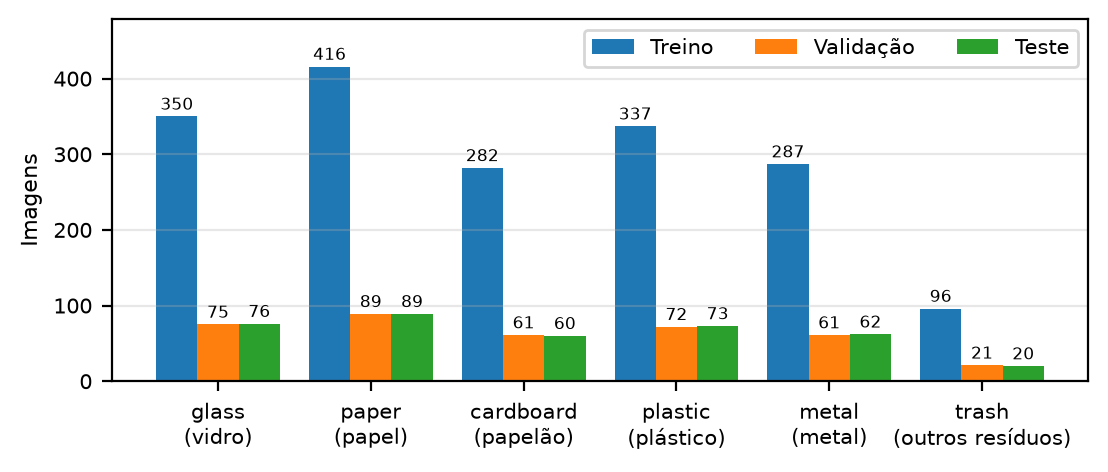

### Dois exemplos de cada classe

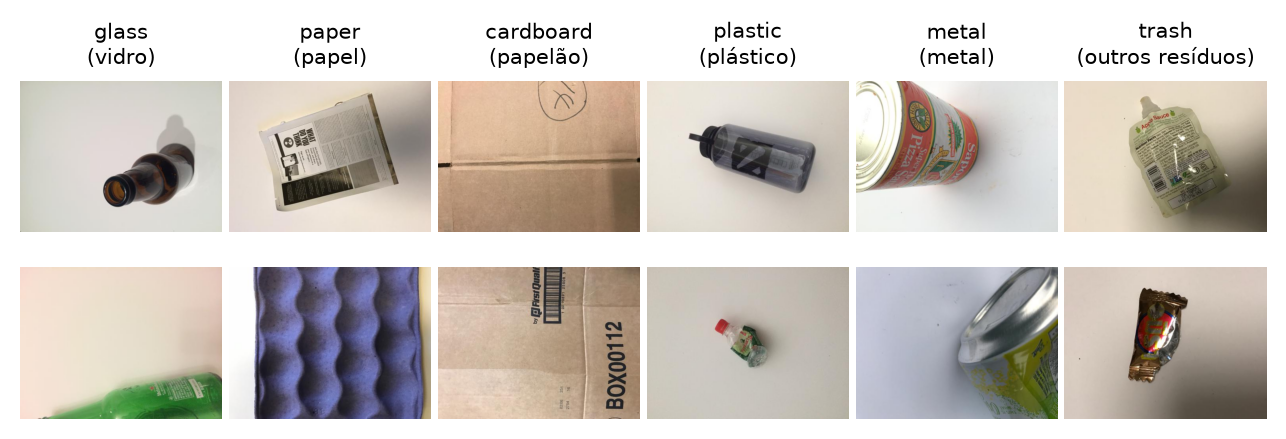

### A mesma imagem nas três resoluções

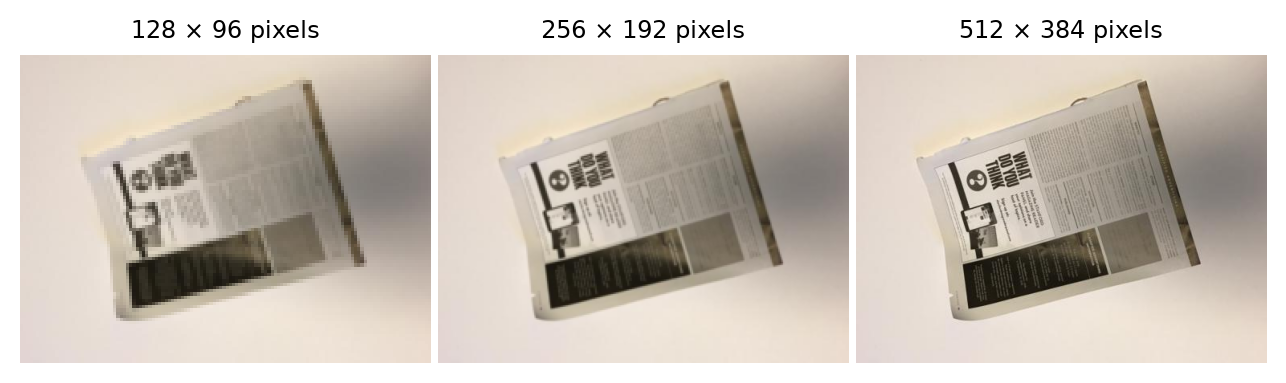

### Curvas de aprendizagem (a linha tracejada marca a época do modelo salvo)

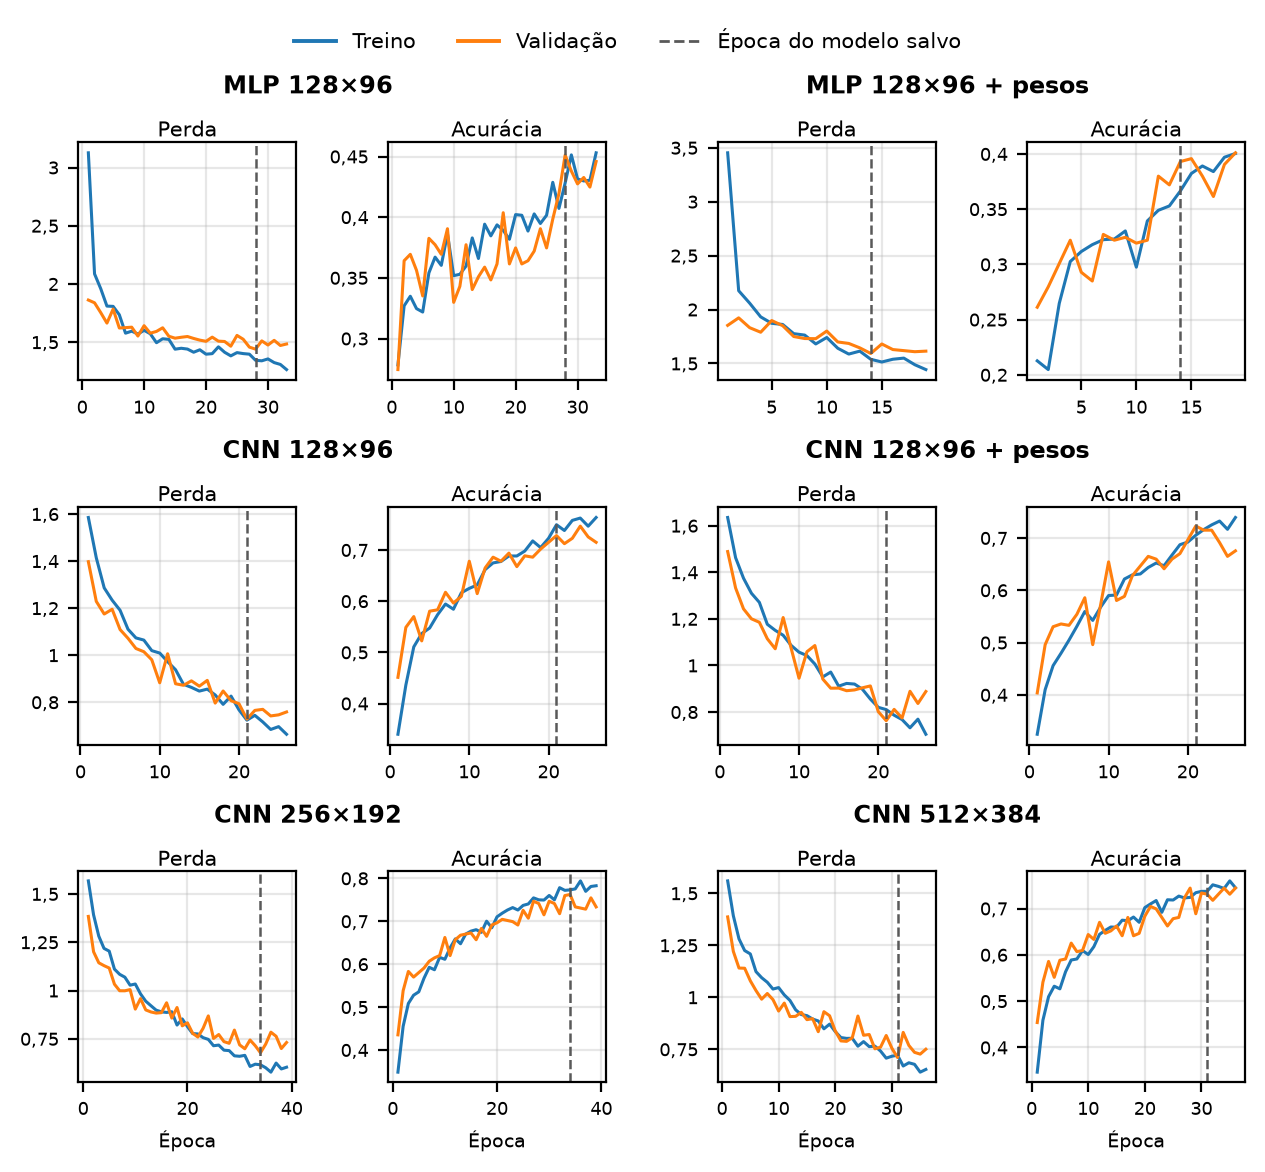

### Matrizes de confusão no teste (contagem e % da linha)

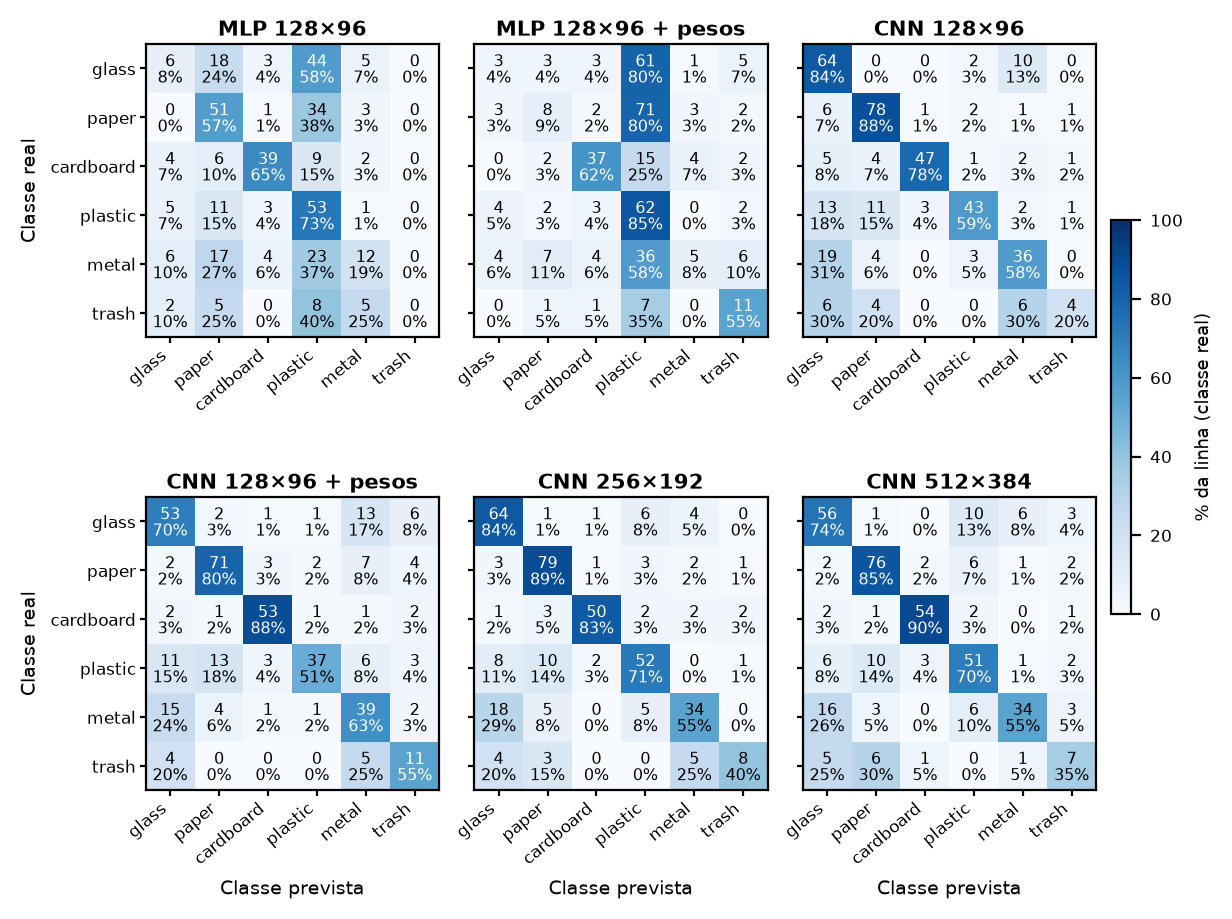

### CNN sem pesos nas três resoluções: desempenho, memória e tempo

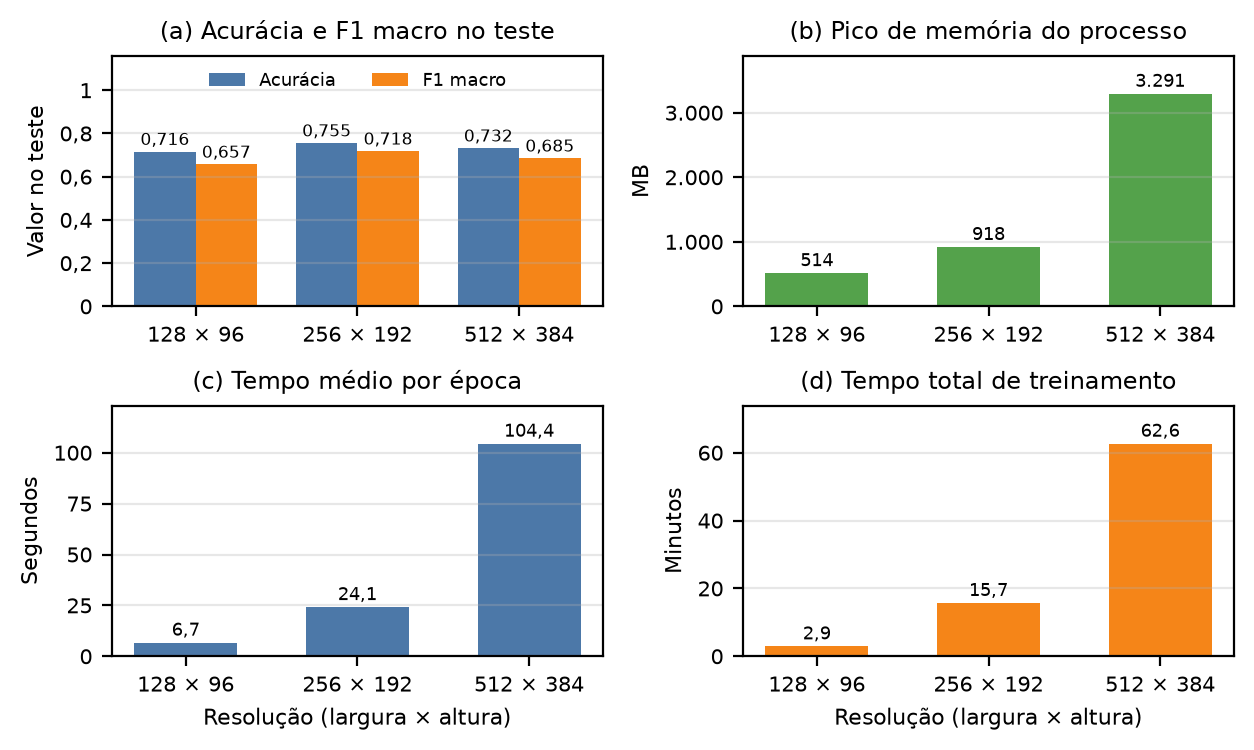

### Erros de teste do modelo escolhido pela validação

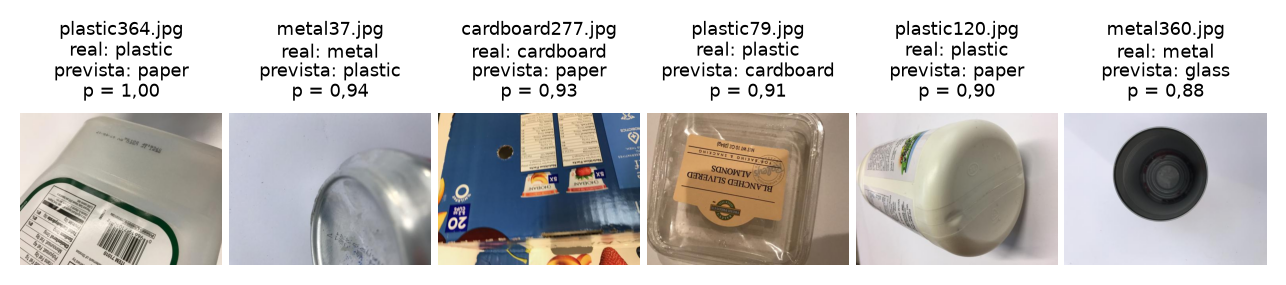

In [3]:
TITULOS = {
    "distribuicao_classes.png": "Imagens por classe em treino, validação e teste",
    "exemplos_classes.png": "Dois exemplos de cada classe",
    "exemplo_resolucoes.png": "A mesma imagem nas três resoluções",
    "curvas_aprendizagem.png": "Curvas de aprendizagem (a linha tracejada marca a época do modelo salvo)",
    "matrizes_confusao.png": "Matrizes de confusão no teste (contagem e % da linha)",
    "efeito_resolucao.png": "CNN sem pesos nas três resoluções: desempenho, memória e tempo",
    "erros_teste.png": "Erros de teste do modelo escolhido pela validação",
}
for nome, titulo in TITULOS.items():
    display(Markdown(f"### {titulo}"))
    display(Image(filename=str(ROOT / "artifacts" / "figuras" / nome)))

In [4]:
erros = resumo["erros"]
print(
    f"{erros['experimento']}: {erros['total_erros_teste']} erros "
    f"em {erros['total_teste']} imagens de teste."
)
display(pd.DataFrame(erros["amostras"]))


cnn_256x192: 93 erros em 380 imagens de teste.


,caminho,classe_real,classe_prevista,probabilidade_prevista
0,plastic/plastic364.jpg,plastic,paper,0.998438
1,metal/metal37.jpg,metal,plastic,0.944133
2,cardboard/cardboard277.jpg,cardboard,paper,0.933329
3,plastic/plastic79.jpg,plastic,cardboard,0.907162
4,plastic/plastic120.jpg,plastic,paper,0.896361
5,metal/metal360.jpg,metal,glass,0.884992


## Análise

[A EQUIPE ESCREVE ESTA SEÇÃO. O enunciado pede métricas, figuras e análise neste notebook. Pontos a cobrir, os mesmos da Discussão do artigo: como MLP e CNN se comportaram em 128 × 96 e o que as curvas mostram; como os pesos de classe afetaram trash e as demais classes; se a resolução maior compensou o tempo e a memória; quais classes foram confundidas e que limitações do dataset dificultam o uso em fotos reais. Use os números das tabelas acima.]

O modelo da figura de erros é o de maior F1 macro na validação, não o de maior acurácia no teste.